## Identification: Homework 4
Name: **Yash Prakash Bhise**
USC ID: **3506429434**

# Reused Setup Code from Homework 3 (Ungraded)

## (1) Time Series Classification: Feature Creation/Extraction

### (a) Dataset

The AReM (Activity Recognition from Multisensor data fusion) dataset was downloaded from the UCI ML Repository: https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29

Dataset contains 7 activity folders (bending1, bending2, cycling, lying, sitting, standing, walking) with 88 total instances. Each instance has 6 time series × 480 values.

Stored at `../data/AReM/`.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

# modeling
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# metrics
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score,
    classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

In [ ]:
# picked directly from Assignment 3
# path to data
data_root = Path("../data/AReM")

# activity folders
act = sorted([d.name for d in data_root.iterdir() if d.is_dir()])
print("Activity folders found:", act)

sam_path = data_root / "bending1" / "dataset1.csv"
sig_cols = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']

def load_instance(filepath):
    df = pd.read_csv(
        filepath,
        comment='#',
        header=None,
        names=['time'] + sig_cols,
        sep=r'[,\s]+',
        on_bad_lines='skip', 
    )
    # coerce to numeric, drop any rows that didn't parse as numbers
    df = df.apply(pd.to_numeric, errors='coerce').dropna()
    return df[sig_cols]

# test
sam = load_instance(sam_path)
print("Sample shape:", sam.shape)
print("First 3 rows:")
print(sam.head(3))
print("Dtypes:", sam.dtypes.tolist())

Activity folders found: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Sample shape: (480, 6)
First 3 rows:
   avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
0      39.25       0.43      22.75       0.43      33.75        1.3
1      39.25       0.43      23.00       0.00      33.00        0.0
2      39.25       0.43      23.25       0.43      33.00        0.0
Dtypes: [dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64'), dtype('float64')]


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(


In [3]:
# picked directly from Assignment 3
# extract int N 
def parse_dataset_number(filepath):
    stem = Path(filepath).stem           # "dataset15"
    return int(stem.replace("dataset", ""))

def build_train_test_split():
    test_files = []
    train_files = []
    
    for a1 in act:
        all_files = glob.glob(str(data_root / a1 / "*.csv"))
        # sort numerically by dataset number
        all_files = sorted(all_files, key=parse_dataset_number)
        
        # how many go to test for activity
        n_test = 2 if a1 in ("bending1", "bending2") else 3
        
        for f in all_files:
            if parse_dataset_number(f) <= n_test:
                test_files.append((f, a1))
            else:
                train_files.append((f, a1))
    
    return train_files, test_files

train_files, test_files = build_train_test_split()
print(f"Train instances: {len(train_files)}")
print(f"Test instances:  {len(test_files)}")

Train instances: 69
Test instances:  19


In [4]:
# picked directly from Assignment 3
# features
ft = ['min', 'max', 'mean', 'median', 'std', 'q1', 'q3']

def ext_ft(df):
    features = {}
    for col in sig_cols:
        series = df[col]
        features[f"{col}_min"] = series.min()
        features[f"{col}_max"] = series.max()
        features[f"{col}_mean"] = series.mean()
        features[f"{col}_median"] = series.median()
        features[f"{col}_std"] = series.std()
        features[f"{col}_q1"] = series.quantile(0.25)
        features[f"{col}_q3"] = series.quantile(0.75)
    return features

# test on one instance (this part was helped and suggested by llm)
test_ft = ext_ft(sam)
print(f"Number of features: {len(test_ft)}") 
print(f"\nFirst 10 feature names: {list(test_ft.keys())[:10]}")
print(f"\nSample values:")
for name, val in list(test_ft.items())[:5]:
    print(f"  {name}: {val:.4f}")

def build_ft_mt(file_list):
    rows = []
    for filepath, label in file_list:
        df = load_instance(filepath)
        feats = ext_ft(df)
        feats['activity'] = label
        feats['filename'] = Path(filepath).name
        rows.append(feats)
    return pd.DataFrame(rows)

Number of features: 42

First 10 feature names: ['avg_rss12_min', 'avg_rss12_max', 'avg_rss12_mean', 'avg_rss12_median', 'avg_rss12_std', 'avg_rss12_q1', 'avg_rss12_q3', 'var_rss12_min', 'var_rss12_max', 'var_rss12_mean']

Sample values:
  avg_rss12_min: 37.2500
  avg_rss12_max: 45.0000
  avg_rss12_mean: 40.6248
  avg_rss12_median: 40.5000
  avg_rss12_std: 1.4770


# Homework 4 Code (Graded)

## Problem 2: Binary and Multiclass Classification

## Problem 2(a): Binary Classification Using Logistic Regression

### 2(a)(i) Scatter plots: features from 1(c)(iv) × time series 1, 2, 6

In [5]:
# time series 1, 2 and 6
ts_1_2_6 = ['avg_rss12', 'var_rss12', 'var_rss23']

# feature types to extract
ft_types = ['min', 'mean', 'max']

# build a 9-feature table on the TRAINING set only
rows_2ai = []
for filepath, label in train_files:
    df = load_instance(filepath)
    row = {}
    for ts in ts_1_2_6: # loop over each time series
        series = df[ts]
        row[f"{ts}_min"]  = series.min()
        row[f"{ts}_mean"] = series.mean()
        row[f"{ts}_max"]  = series.max()
    # binary label: bending vs other
    row['label'] = 'bending' if label in ('bending1', 'bending2') else 'other'
    rows_2ai.append(row)

df_2ai = pd.DataFrame(rows_2ai)
print("Shape:", df_2ai.shape)
print("\nLabel counts:")
print(df_2ai['label'].value_counts())
print("\nFirst 3 rows:")
print(df_2ai.head(3))

Shape: (69, 10)

Label counts:
label
other      60
bending     9
Name: count, dtype: int64

First 3 rows:
   avg_rss12_min  avg_rss12_mean  avg_rss12_max  var_rss12_min  \
0           35.0       43.954500          47.40            0.0   
1           33.0       42.179812          47.75            0.0   
2           33.0       41.678063          45.75            0.0   

   var_rss12_mean  var_rss12_max  var_rss23_min  var_rss23_mean  \
0        0.426250           1.70            0.0        0.493292   
1        0.696042           3.00            0.0        0.613521   
2        0.535979           2.83            0.0        0.383292   

   var_rss23_max    label  
0           1.79  bending  
1           2.18  bending  
2           1.79  bending  


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

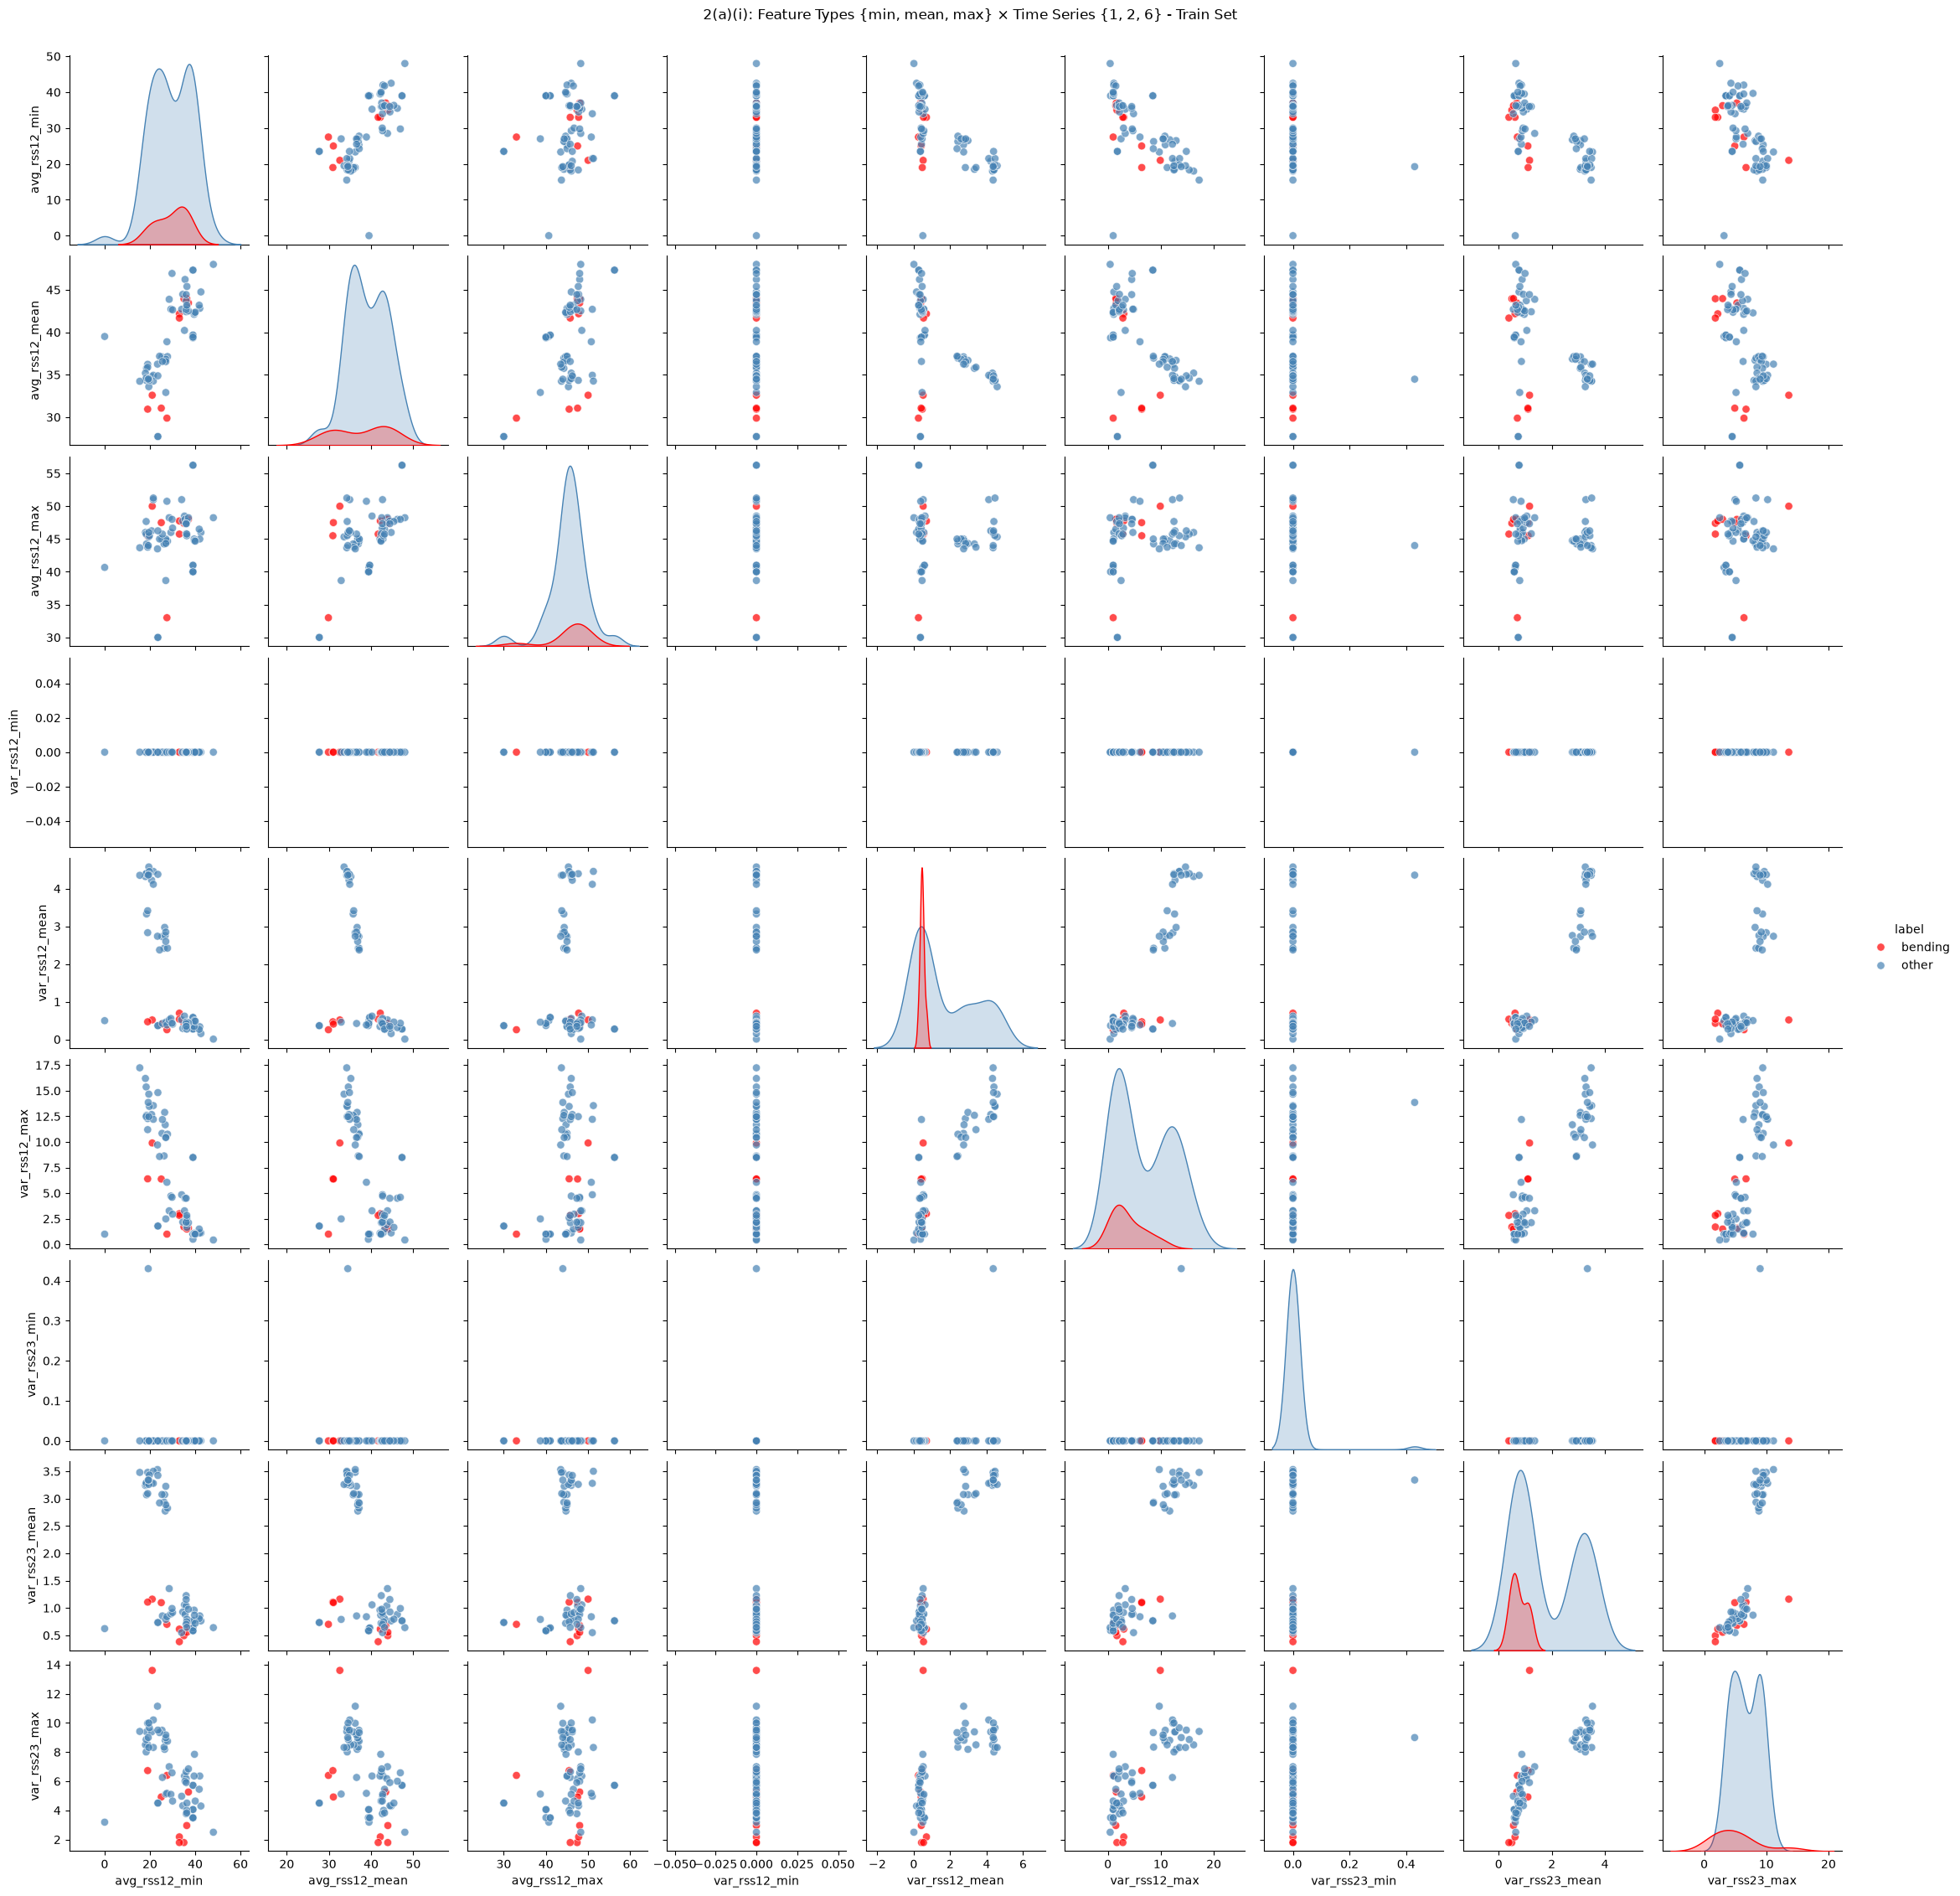

In [6]:
# pairplot of features for 2(a)(i)
ft_cols_2ai = [c for c in df_2ai.columns if c != 'label']

sns.pairplot(
    df_2ai,
    vars=ft_cols_2ai,
    hue='label',
    palette={'bending': 'red', 'other': 'steelblue'},
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 45},
)
plt.suptitle("2(a)(i): Feature Types {min, mean, max} × Time Series {1, 2, 6} - Train Set", 
             y=1.01, fontsize=12)
plt.show()

**Observations from the pairplot for (2(a)(i)):**

- The training set is highly imbalanced: 9 bending instances vs 60 other activities
- Even with few bending points visible separation appears on several feature pairs.
- Features from `var_rss23` (time series 6) show the strongest tendency to separate bending from other activities?

### 2(a)(ii): Scatter plots with each time series split in half

Each 480-point time series is split into two approximately equal halves (240 points each). The 6 original time series become 12.

In [7]:
# build the feature table for 2(a)(ii)
rows_2aii = []
for filepath, label in train_files:
    df = load_instance(filepath)
    n = len(df)
    half = n // 2
    
    row = {}
    for ts in ts_1_2_6: # avg_rss12, var_rss12, var_rss23
        series = df[ts]
        
        # first half
        s1 = series.iloc[:half]
        row[f"{ts}_h1_min"]  = s1.min()
        row[f"{ts}_h1_mean"] = s1.mean()
        row[f"{ts}_h1_max"]  = s1.max()
        
        # second half
        s2 = series.iloc[half:]
        row[f"{ts}_h2_min"]  = s2.min()
        row[f"{ts}_h2_mean"] = s2.mean()
        row[f"{ts}_h2_max"]  = s2.max()
    
    row['label'] = 'bending' if label in ('bending1', 'bending2') else 'other'
    rows_2aii.append(row)

df_2aii = pd.DataFrame(rows_2aii)
print("Shape:", df_2aii.shape)
print("\nLabel counts:")
print(df_2aii['label'].value_counts())
print("\nFirst 3 rows (first 5 cols):")
print(df_2aii.iloc[:3, :5])

Shape: (69, 19)

Label counts:
label
other      60
bending     9
Name: count, dtype: int64

First 3 rows (first 5 cols):
   avg_rss12_h1_min  avg_rss12_h1_mean  avg_rss12_h1_max  avg_rss12_h2_min  \
0             36.50          44.057167             46.50             35.00   
1             33.75          43.278875             47.75             33.00   
2             33.00          41.621208             45.75             39.25   

   avg_rss12_h2_mean  
0          43.851833  
1          41.080750  
2          41.734917  


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

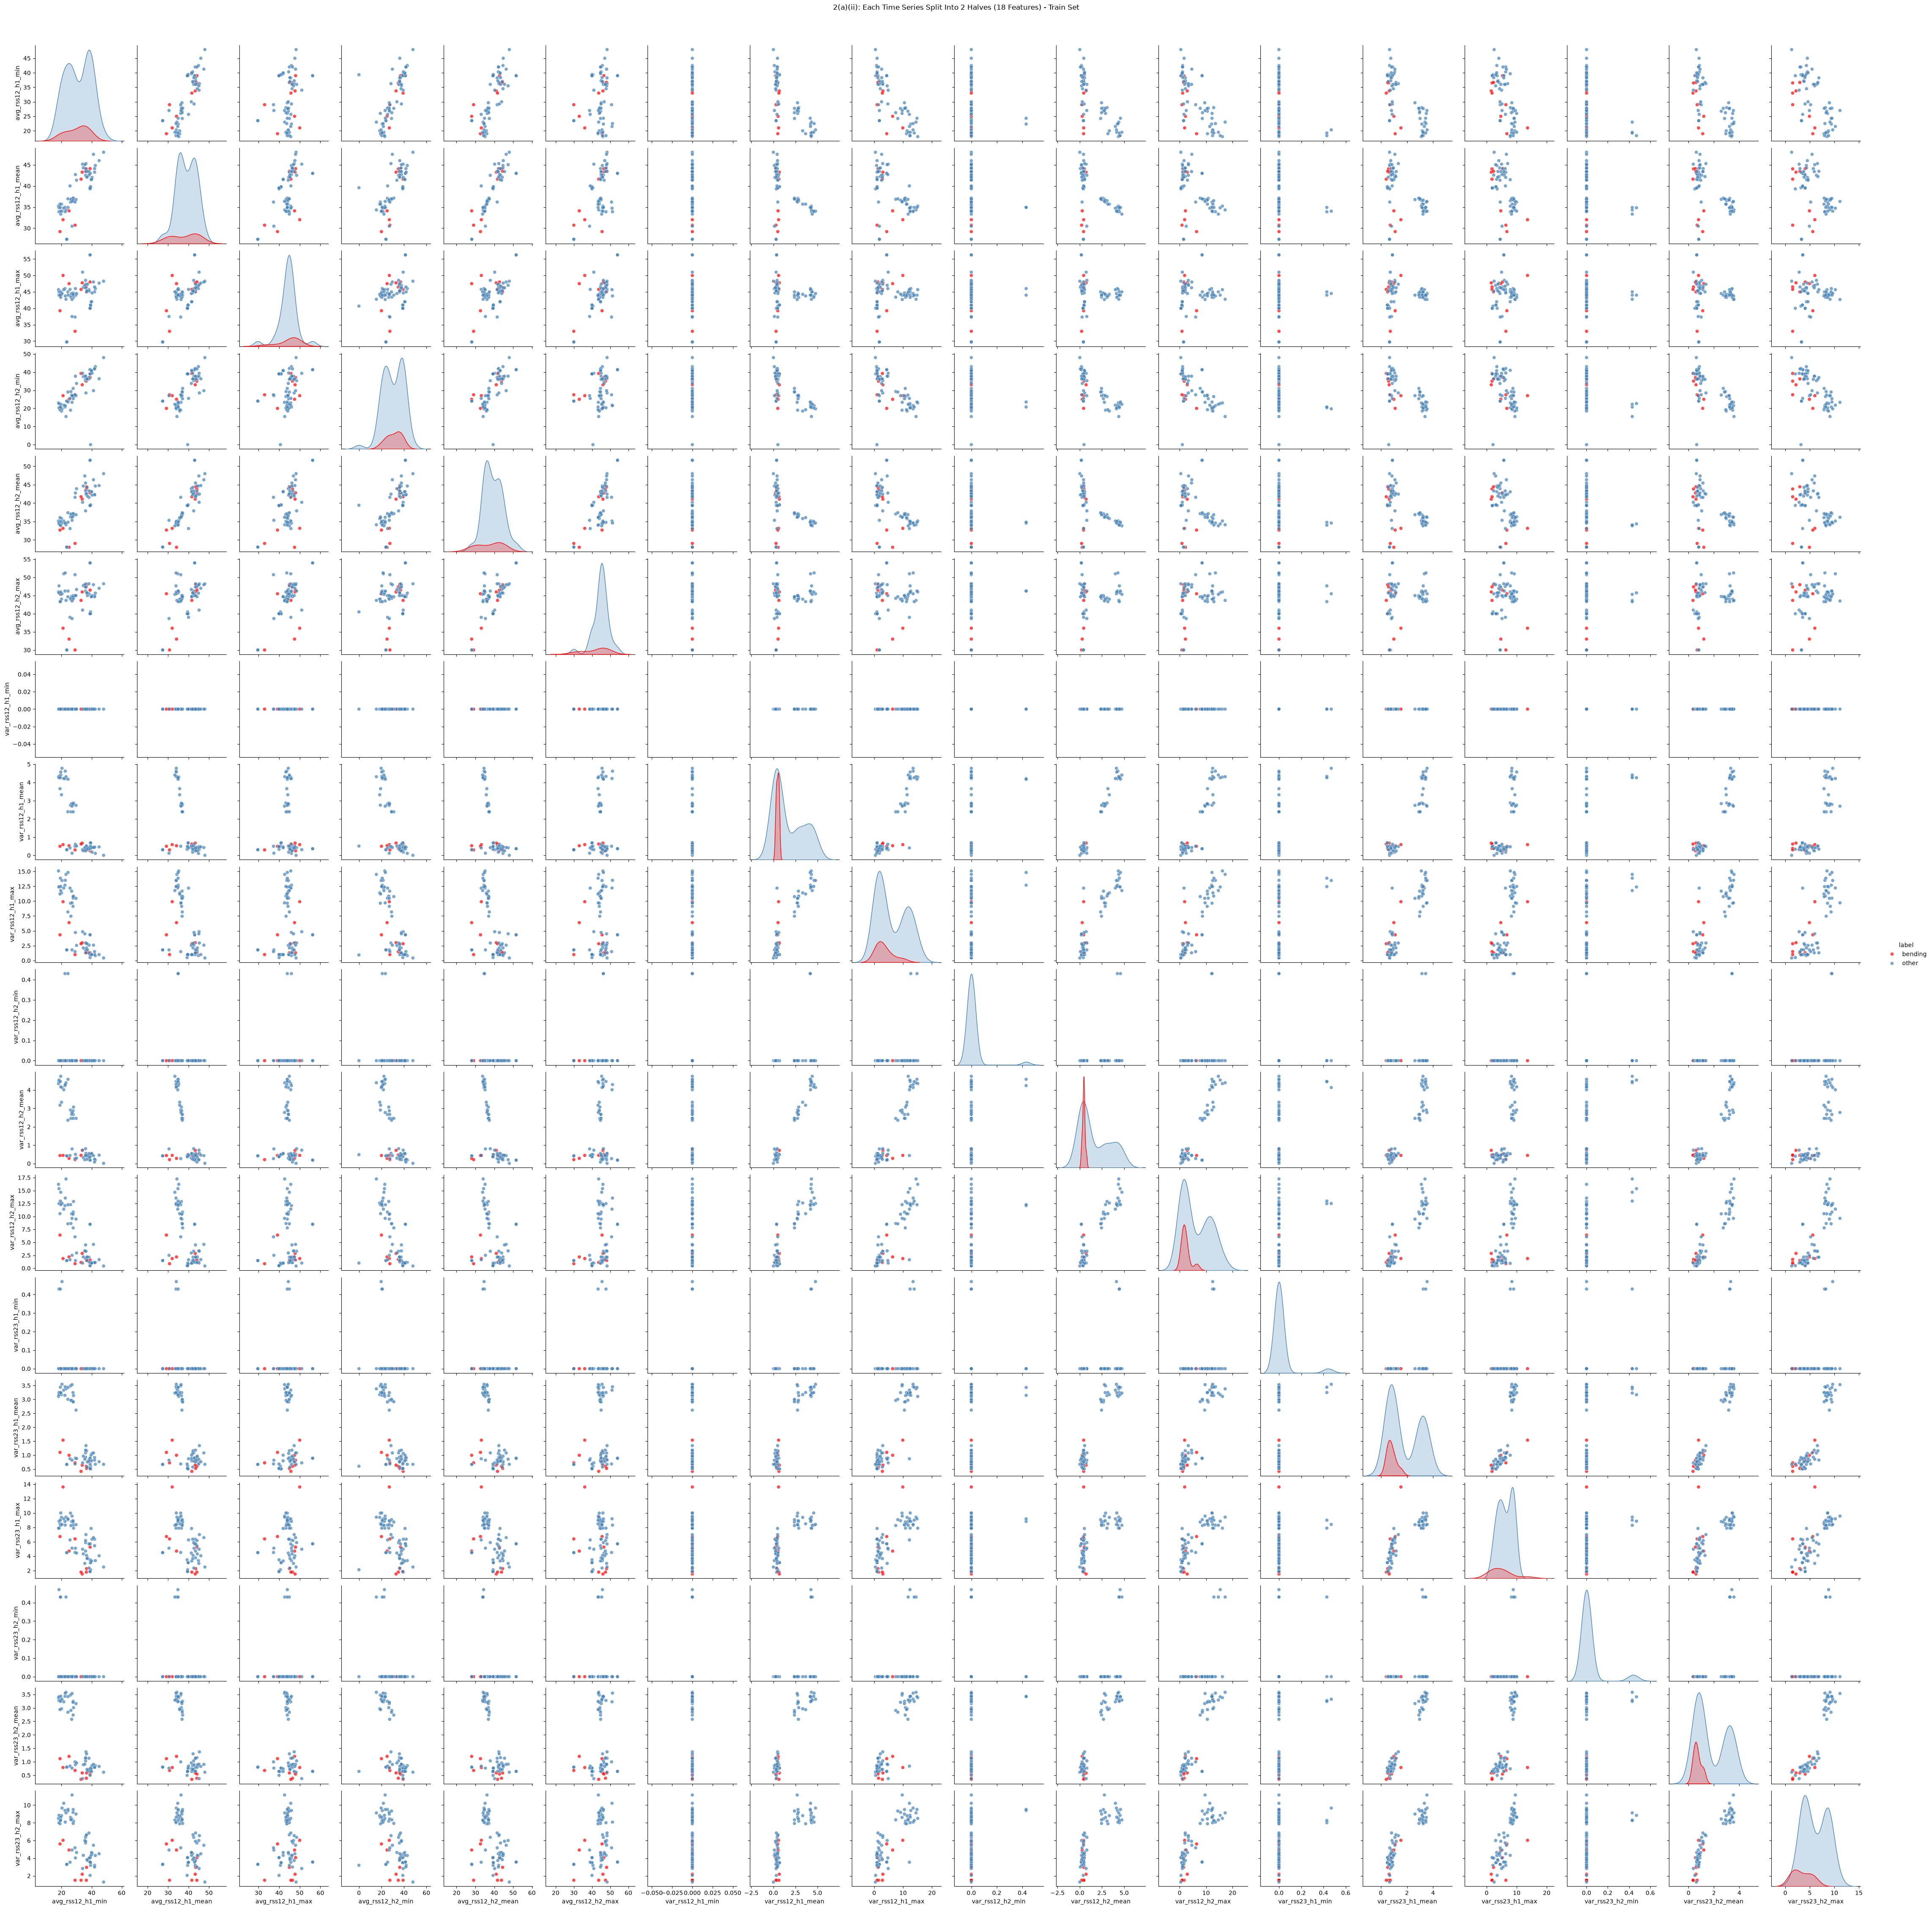

In [8]:
# pairplot of features for 2(a)(ii)
ft_cols_2aii = [c for c in df_2aii.columns if c != 'label']

sns.pairplot(
    df_2aii,
    vars=ft_cols_2aii,
    hue='label',
    palette={'bending': 'red', 'other': 'steelblue'},
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 35},
)
plt.suptitle("2(a)(ii): Each Time Series Split Into 2 Halves (18 Features) - Train Set",
             y=1.01, fontsize=12)
plt.show()

**Observations (2(a)(ii)): comparison with 2(a)(i):**

- The matrix is now 18×18 instead of 9×9 since each time series contributes two halves.
- Many `_h1` vs `_h2` pairings for the same (time series, feature type) lie close to the diagonal, indicating that for most instances the two halves give similar statistics. This suggests the signals are **roughly stationary within a single recording**.

### 2(a)(iii) Logistic Regression over l in {1,...,20} with p-value-based / backward feature selection

We fit a logistic regression classifier where each time series is split into *l* equal segments (l = 1, 2, ..., 20). We use Recursive Feature Elimination (RFE) as a form of backward selection to drop features to a target count of *p*, and use **5-fold stratified cross-validation** on the training set to find the best pair of (l, p).

**Right vs wrong way to cross-validate:**
- **Wrong way:** We perform feature selection once on the full training set, then run 5-fold CV using only the pre-selected features. This could leak the validation folds into feature selection hence inflating the CV accuracy.
- **Right way:** We can perform feature selection **inside each CV fold** using only the training portion of that fold. The validation portion remains unseen until the final scoring. We implement this by combinig RFE and LogisticRegression in a `sklearn.pipeline.Pipeline` and passing it to `cross_val_score` which fits the entire pipeline on each training fold.

**Stratified CV:** With 9 bending vs 60 other training instances the standard k-fold could leave some folds with zero bending samples. `StratifiedKFold` guarantees proportional class representation per fold. (used an LLM here to research more)

In [9]:
## llm assisted code for 2(a)(iii) (I had a lot of issues to build this particular function while utilizing the ext_ft function from HW3)
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

def build_matrix_L(file_list, L):
    """
    Build feature matrix at a given L by splitting each time series into L segments
    and calling HW3's ext_ft on each segment slice. Inline logic for authenticity.
    Returns X (numpy array), y (numpy array), feature_names (list).
    """
    rows = []
    labels = []
    for filepath, label in file_list:
        df = load_instance(filepath)
        n = len(df)
        seg_size = n // L

        ## llm assisted bugfixing here
        combined = {}
        for seg_idx in range(L):
            start = seg_idx * seg_size
            end = (seg_idx + 1) * seg_size if seg_idx < L - 1 else n
            segment_df = df.iloc[start:end]
            
            # reuse HW3's ext_ft on this segment slice
            seg_feats = ext_ft(segment_df)
            # prefix with segment index to make names unique
            for k, v in seg_feats.items():
                combined[f"{k}_seg{seg_idx+1}"] = v
        
        rows.append(combined)
        labels.append(1 if label in ('bending1', 'bending2') else 0)
    
    X_df = pd.DataFrame(rows)
    return X_df.values, np.array(labels), list(X_df.columns)

# sanity check
X_test_L1, y_test_L1, feat_names_L1 = build_matrix_L(train_files, L=1)
print(f"L=1: X shape {X_test_L1.shape}, y shape {y_test_L1.shape}")
print(f"y distribution: {Counter(y_test_L1)}")

X_test_L5, _, _ = build_matrix_L(train_files, L=5)
print(f"L=5: X shape {X_test_L5.shape}")

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=1: X shape (69, 42), y shape (69,)
y distribution: Counter({np.int64(0): 60, np.int64(1): 9})


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=5: X shape (69, 210)


In [10]:
# CV grid search over L and p
L_values = [1, 2, 5, 10, 15, 20]
p_values = [3, 5, 10, 20]        # target number of features after RFE

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# store
cv_results = []

for L in L_values:
    X, y, feat_names = build_matrix_L(train_files, L)
    n_total_features = X.shape[1]
    
    for p in p_values:
        # skip if asking for more features than exist
        if p > n_total_features:
            continue
        
        #  right way
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('rfe', RFE(
                estimator=LogisticRegression(solver='liblinear', max_iter=1000, C=1e6),  # weak reg
                n_features_to_select=p,
                step=max(1, (n_total_features - p) // 10),   # faster for big L
            )),
            ('clf', LogisticRegression(
                solver='liblinear', max_iter=1000, C=1e6
            )),
        ])
        
        # stratified 5-fold CV
        scores = cross_val_score(pipeline, X, y, cv=skf, scoring='accuracy', n_jobs=-1)
        
        cv_results.append({ # store results
            'L': L,
            'total_features': n_total_features,
            'p': p,
            'cv_accuracy_mean': round(scores.mean(), 4),
            'cv_accuracy_std':  round(scores.std(),  4),
        })
        print(f"L={L:2d} ({n_total_features:3d} feats), p={p:3d}: "
              f"CV accuracy = {scores.mean():.4f} ± {scores.std():.4f}")

cv_results_df = pd.DataFrame(cv_results)
cv_results_df

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 1 ( 42 feats), p=  3: CV accuracy = 0.9571 ± 0.0571
L= 1 ( 42 feats), p=  5: CV accuracy = 0.9429 ± 0.0535
L= 1 ( 42 feats), p= 10: CV accuracy = 0.9429 ± 0.0535
L= 1 ( 42 feats), p= 20: CV accuracy = 0.9714 ± 0.0350


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 2 ( 84 feats), p=  3: CV accuracy = 0.9286 ± 0.0639
L= 2 ( 84 feats), p=  5: CV accuracy = 0.9429 ± 0.0535
L= 2 ( 84 feats), p= 10: CV accuracy = 0.9560 ± 0.0359
L= 2 ( 84 feats), p= 20: CV accuracy = 0.9275 ± 0.0022


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

...

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=15 (630 feats), p=  3: CV accuracy = 0.9143 ± 0.0535
L=15 (630 feats), p=  5: CV accuracy = 0.9286 ± 0.0452
L=15 (630 feats), p= 10: CV accuracy = 0.9429 ± 0.0535
L=15 (630 feats), p= 20: CV accuracy = 0.9286 ± 0.0639


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=20 (840 feats), p=  3: CV accuracy = 0.8824 ± 0.0775
L=20 (840 feats), p=  5: CV accuracy = 0.8681 ± 0.0869
L=20 (840 feats), p= 10: CV accuracy = 0.8835 ± 0.0738
L=20 (840 feats), p= 20: CV accuracy = 0.9571 ± 0.0571


,L,total_features,p,cv_accuracy_mean,cv_accuracy_std
0,1,42,3,0.9571,0.0571
1,1,42,5,0.9429,0.0535
2,1,42,10,0.9429,0.0535
3,1,42,20,0.9714,0.0350
4,2,84,3,0.9286,0.0639
5,2,84,5,0.9429,0.0535
6,2,84,10,0.9560,0.0359
7,2,84,20,0.9275,0.0022
8,5,210,3,0.9132,0.0281
9,5,210,5,0.9275,0.0452


In [11]:
best_row = cv_results_df.iloc[cv_results_df['cv_accuracy_mean'].idxmax()] # optimal L* and p* based on CV accuracy
L_star = int(best_row['L'])
p_star = int(best_row['p'])
best_cv_acc = best_row['cv_accuracy_mean']

print(f"Best L* = {L_star}, Best p* = {p_star}")
print(f"Best 5-fold stratified CV accuracy: {best_cv_acc:.4f}")

Best L* = 1, Best p* = 20
Best 5-fold stratified CV accuracy: 0.9714


### 2(a)(iv): Confusion matrix, ROC, AUC on train data + coefficients and p-values

In [12]:
# refit pipeline on ALL training data at best L*, p*
X_train_star, y_train_star, feat_names_star = build_matrix_L(train_files, L_star)

final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe', RFE(
        estimator=LogisticRegression(solver='liblinear', max_iter=1000, C=1e6),
        n_features_to_select=p_star,
        step=1,
    )),
    ('clf', LogisticRegression(solver='liblinear', max_iter=1000, C=1e6)),
])
final_pipeline.fit(X_train_star, y_train_star)

# RFE selected feature
selected_mask = final_pipeline.named_steps['rfe'].support_
selected_names = [n for n, keep in zip(feat_names_star, selected_mask) if keep]
print(f"Selected {sum(selected_mask)} features out of {len(feat_names_star)}:")
for i, name in enumerate(selected_names, 1):
    print(f"  {i:2d}. {name}")

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

Selected 20 features out of 42:
   1. avg_rss12_min_seg1
   2. avg_rss12_max_seg1
   3. avg_rss12_mean_seg1
   4. avg_rss12_q3_seg1
   5. var_rss12_max_seg1
   6. var_rss12_median_seg1
   7. avg_rss13_min_seg1
   8. avg_rss13_max_seg1
   9. avg_rss13_std_seg1
  10. avg_rss13_q3_seg1
  11. var_rss13_max_seg1
  12. var_rss13_mean_seg1
  13. var_rss13_median_seg1
  14. var_rss13_q1_seg1
  15. avg_rss23_min_seg1
  16. avg_rss23_max_seg1
  17. avg_rss23_mean_seg1
  18. avg_rss23_q1_seg1
  19. var_rss23_std_seg1
  20. var_rss23_q1_seg1


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

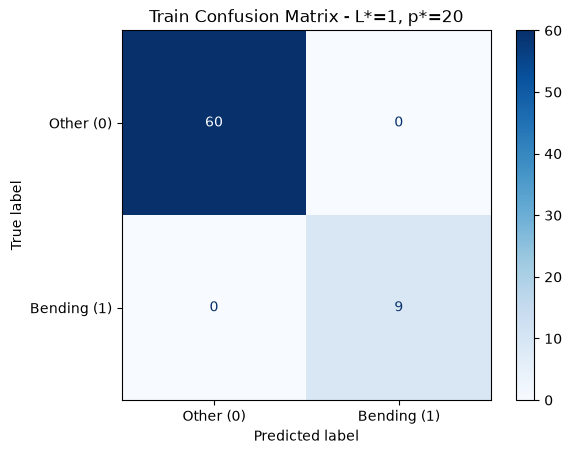

Train - TN=60, FP=0, FN=0, TP=9
Train accuracy: 1.0000
Train precision: 1.0000
Train recall: 1.0000
Train F1: 1.0000


In [13]:
# predict on train set
train_pred = final_pipeline.predict(X_train_star)
train_proba = final_pipeline.predict_proba(X_train_star)[:, 1]

# confusion matrix
cm_train = confusion_matrix(y_train_star, train_pred)
disp = ConfusionMatrixDisplay(cm_train, display_labels=['Other (0)', 'Bending (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Train Confusion Matrix - L*={L_star}, p*={p_star}')
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm_train.ravel()
print(f"Train - TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Train accuracy: {accuracy_score(y_train_star, train_pred):.4f}")
print(f"Train precision: {precision_score(y_train_star, train_pred):.4f}")
print(f"Train recall: {recall_score(y_train_star, train_pred):.4f}")
print(f"Train F1: {f1_score(y_train_star, train_pred):.4f}")

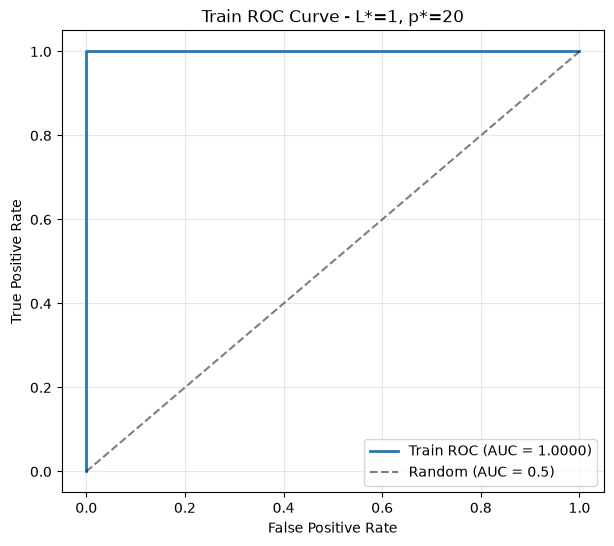

Train AUC: 1.0000


In [14]:
fpr, tpr, _ = roc_curve(y_train_star, train_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='tab:blue', linewidth=2, label=f'Train ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Train ROC Curve - L*={L_star}, p*={p_star}')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Train AUC: {roc_auc:.4f}")

In [15]:
## llm assisted bugfixing again (struggled a lot with this part of the code)

import statsmodels.api as sm

## llm helped me simplify this part of the code
# scale the training data
scaler_fit = final_pipeline.named_steps['scaler']
X_scaled = scaler_fit.transform(X_train_star)

# keep only the 20 features RFE selected in the cell above
X_selected = X_scaled[:, selected_mask]

# fit via statsmodels for coefficients and p-values
X_with_const = sm.add_constant(X_selected)
logit_model = sm.Logit(y_train_star, X_with_const).fit(disp=False, maxiter=500)

# print the full summary table (statsmodels had this functionality built-in for the summary with great formatting)
print(logit_model.summary(xname=['intercept'] + selected_names))

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       48
Method:                           MLE   Df Model:                           20
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        22:23:39   Log-Likelihood:            -4.5312e-11
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 7.012e-05
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
intercept               -31.8214   1.25e+06  -2.54e-05      1.000   -2.45e+06    2.45e+06
avg_rss12_min_seg1       -6.4846    3.2e+06  -2.03e-06      1.000   -6.27e+06    6.27e+06
avg_rss1

/opt/miniconda3/envs/dsci552/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/envs/dsci552/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/envs/dsci552/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/envs/dsci552/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/miniconda3/envs/dsci552/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separatio

**Observations for 2(a)(vi)):**
statsmodels did produce a table, but it also issued a `CompleteSeparationError` warning at the bottom and reported `converged: False`. The important signals in the table:
- **Pseudo R² = 1.000** and **Log-Likelihood = 0** mean the model fits the training set perfectly.
- **Standard errors are astronomical** 
- **All p-values = 1.000** 
- **95% CIs span ±millions**

### 2(a)(v) Evaluate on the test set

The classifier is tested on the held-out 19-instance test set using the same (L* = 1, p* = 20) model fit on the training set.

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

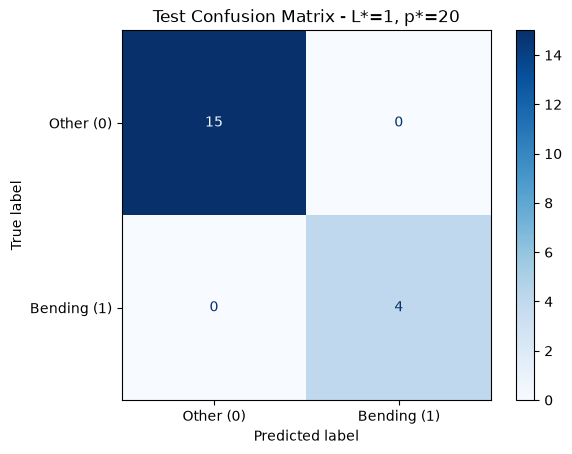

Test - TN=15, FP=0, FN=0, TP=4
Test accuracy: 1.0000
Test precision: 1.0000
Test recall: 1.0000
Test F1: 1.0000

For comparison: 5-fold CV accuracy from 2(a)(iii): 0.9714


In [16]:
# build test matrix at L*
X_test_star, y_test_star, _ = build_matrix_L(test_files, L_star)

# use the already-fit pipeline (fit on train) to predict on test
test_pred = final_pipeline.predict(X_test_star)
test_proba = final_pipeline.predict_proba(X_test_star)[:, 1]

# confusion matrix
cm_test = confusion_matrix(y_test_star, test_pred)
disp = ConfusionMatrixDisplay(cm_test, display_labels=['Other (0)', 'Bending (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Test Confusion Matrix - L*={L_star}, p*={p_star}')
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm_test.ravel()
print(f"Test - TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Test accuracy: {accuracy_score(y_test_star, test_pred):.4f}")
print(f"Test precision: {precision_score(y_test_star, test_pred):.4f}")
print(f"Test recall: {recall_score(y_test_star, test_pred):.4f}")
print(f"Test F1: {f1_score(y_test_star, test_pred):.4f}")
print(f"\nFor comparison: 5-fold CV accuracy from 2(a)(iii): {best_cv_acc:.4f}")

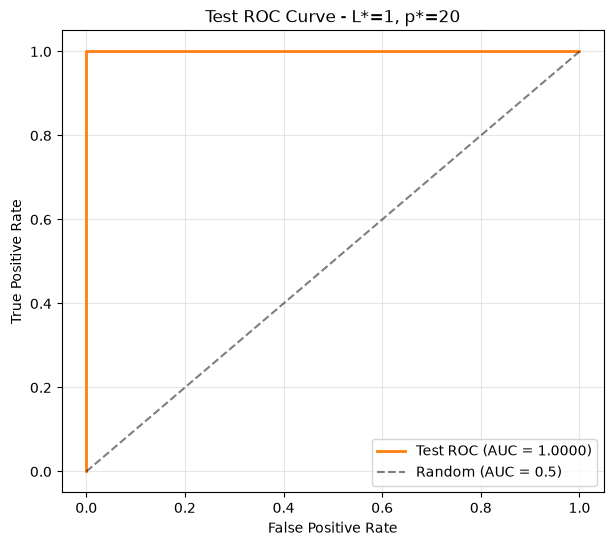

Test AUC: 1.0000


In [17]:
fpr_test, tpr_test, _ = roc_curve(y_test_star, test_proba)
roc_auc_test = auc(fpr_test, tpr_test)

## llm assist here
plt.figure(figsize=(7, 6))
plt.plot(fpr_test, tpr_test, color='tab:orange', linewidth=2, label=f'Test ROC (AUC = {roc_auc_test:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Test ROC Curve - L*={L_star}, p*={p_star}')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Test AUC: {roc_auc_test:.4f}")

**2(a)(v) Observations - Test vs CV comparison:**

- Test accuracy: 1.0000 (19/19 correct)
- 5-fold CV accuracy from 2(a)(iii): 0.9714
- Test AUC: 1.0000

Test performance exceeds CV accuracy which could happen here because the test set is small (19 instances, 4 bending vs 15 other)

### 2(a)(vi) Are the classes well-separated enough to cause instability?

**Yes.** The evidence is in the above cells.

- `converged: False`
- `Pseudo R² = 1.000` and `Log-Likelihood ≈ -4.5e-11` shows that the model fits every training instance perfectly
- **Standard errors on all coefficients are on the order of 10⁶** 
- **All p-values go to 1.000** 

### 2(a)(vii) Imbalanced classes: case-control sampling

The confusion matrix shows severe class imbalance: training has 60 "other" vs 9 "bending" instances (≈ 87% / 13% split). Case-control sampling attempts to rebalance this.

**Approach:** Oversampling the bending (minority) class in the training set by resampling with replacement until class sizes are equal (60 vs 60), then retrain the same L1-free pipeline. Report new confusion matrix, ROC, and AUC on the test set.

Rebalanced train: Counter({np.int64(0): 60, np.int64(1): 60})


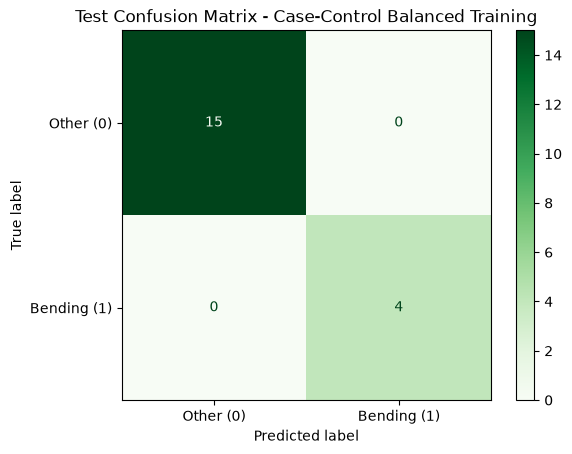

TN=15, FP=0, FN=0, TP=4
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1: 1.0000


In [18]:
from sklearn.utils import resample

# separate train by class
X_other   = X_train_star[y_train_star == 0]
X_bending = X_train_star[y_train_star == 1]

# oversample bending to match the number of other instances
X_bending_up = resample(X_bending, replace=True, n_samples=len(X_other), random_state=42)

# rebuild balanced training set
X_train_bal = np.vstack([X_other, X_bending_up])
y_train_bal = np.array([0] * len(X_other) + [1] * len(X_bending_up))

print(f"Rebalanced train: {Counter(y_train_bal)}")

# refit the same pipeline on balanced data we have now
balanced_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe', RFE(LogisticRegression(solver='liblinear', max_iter=1000, C=1e6), # llm bugfix
                n_features_to_select=p_star, step=1)),
    ('clf', LogisticRegression(solver='liblinear', max_iter=1000, C=1e6)),
])
balanced_pipeline.fit(X_train_bal, y_train_bal)

# evaluate on the og test set (not the balanced one)
bal_test_pred  = balanced_pipeline.predict(X_test_star)
bal_test_proba = balanced_pipeline.predict_proba(X_test_star)[:, 1]

# confusion matrix
cm_bal = confusion_matrix(y_test_star, bal_test_pred)
disp = ConfusionMatrixDisplay(cm_bal, display_labels=['Other (0)', 'Bending (1)'])
disp.plot(cmap='Greens', values_format='d')
plt.title(f'Test Confusion Matrix - Case-Control Balanced Training')
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm_bal.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy: {accuracy_score(y_test_star, bal_test_pred):.4f}")
print(f"Precision: {precision_score(y_test_star, bal_test_pred):.4f}")
print(f"Recall: {recall_score(y_test_star, bal_test_pred):.4f}")
print(f"F1: {f1_score(y_test_star, bal_test_pred):.4f}")

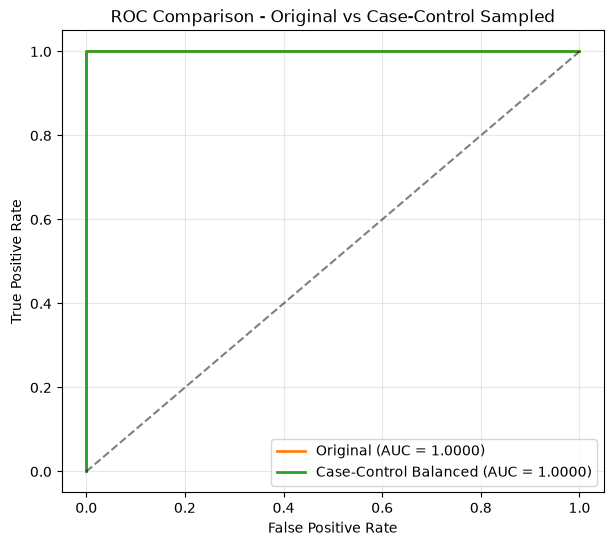

Original AUC: 1.0000
Case-Control AUC: 1.0000


In [19]:
fpr_bal, tpr_bal, _ = roc_curve(y_test_star, bal_test_proba) ## llm assist here for bugfixing
roc_auc_bal = auc(fpr_bal, tpr_bal)

plt.figure(figsize=(7, 6))
plt.plot(fpr_test, tpr_test, color='tab:orange', linewidth=2, 
         label=f'Original (AUC = {roc_auc_test:.4f})')
plt.plot(fpr_bal, tpr_bal, color='tab:green', linewidth=2,
         label=f'Case-Control Balanced (AUC = {roc_auc_bal:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Comparison - Original vs Case-Control Sampled')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Original AUC: {roc_auc_test:.4f}")
print(f"Case-Control AUC: {roc_auc_bal:.4f}")

**2(a)(vii) Observations:**

- Rebalancing with case-control oversampling produced test metrics as follows, accuracy = 1.0000, precision = 1.0000, recall = 1.0000, F1 = 1.0000, AUC = 1.0000.
- Compared to the original (unbalanced) model, AUC is 1 for both?

## Problem 2(b) - Binary Classification Using L1-Penalized Logistic Regression

### 2(b)(i) Repeat 2(a)(iii) with L1 penalty

Instead of RFE-based feature selection (as in 2(a)(iii)), we use L1 (lasso) penalty on logistic regression. L1 shrinks small coefficients to exactly zero, giving automatic feature selection.

**Cross-validation:** For each L in {1, 2, 5, 10, 15, 20}, use `LogisticRegressionCV` which internally runs 5-fold stratified CV over 10 values of C (= 1/lambda)

In [20]:
# search grid
L_values_b = [1, 2, 5, 10, 15, 20]

cv_results_b = []

for L in L_values_b:
    X, y, feat_names = build_matrix_L(train_files, L)
    
    # standardize features
    scaler_b = StandardScaler()
    X_scaled = scaler_b.fit_transform(X)

    ## llm assisted bugfixing here 
    # L1 logistic regression with internal 5-fold CV over 10 C values
    clf_cv = LogisticRegressionCV(
        Cs=10,
        penalty='l1',
        solver='saga',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='accuracy',
        max_iter=5000,
        random_state=42,
        n_jobs=-1,
    )
    clf_cv.fit(X_scaled, y)
    
    # best C and mean CV score at that C
    best_C = clf_cv.C_[0]
    cv_scores = clf_cv.scores_[1].mean(axis=0)  # mean across folds for each C
    best_cv_score = cv_scores.max()
    n_nonzero = np.sum(clf_cv.coef_ != 0)
    
    cv_results_b.append({
        'L': L,
        'total_features': X.shape[1],
        'best_C': round(best_C, 4),
        'best_lambda': round(1/best_C, 4),
        'cv_accuracy': round(best_cv_score, 4),
        'nonzero_coefs': int(n_nonzero),
    })
    
    print(f"L={L:2d} ({X.shape[1]:3d} feats) -> C={best_C:.4f}, "
          f"CV acc={best_cv_score:.4f}, nonzero β's = {n_nonzero}")

cv_results_b_df = pd.DataFrame(cv_results_b)
cv_results_b_df

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 1 ( 42 feats) -> C=21.5443, CV acc=0.9714, nonzero β's = 22


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 2 ( 84 feats) -> C=2.7826, CV acc=0.9571, nonzero β's = 13


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

...

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=15 (630 feats) -> C=21.5443, CV acc=0.9429, nonzero β's = 117


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=20 (840 feats) -> C=21.5443, CV acc=0.9714, nonzero β's = 322


,L,total_features,best_C,best_lambda,cv_accuracy,nonzero_coefs
0,1,42,21.5443,0.0464,0.9714,22
1,2,84,2.7826,0.3594,0.9571,13
2,5,210,21.5443,0.0464,0.9418,81
3,10,420,21.5443,0.0464,0.9571,114
4,15,630,21.5443,0.0464,0.9429,117
5,20,840,21.5443,0.0464,0.9714,322


In [21]:
# pick best (L, C)
best_row_b = cv_results_b_df.iloc[cv_results_b_df['cv_accuracy'].idxmax()]
L_star_b = int(best_row_b['L'])
C_star_b = best_row_b['best_C']
cv_acc_b = best_row_b['cv_accuracy']

print(f"Best L* = {L_star_b}, Best C* = {C_star_b:.4f} (λ = {1/C_star_b:.4f})")
print(f"Best 5-fold CV accuracy: {cv_acc_b:.4f}")

# build train and test matrices at L*
X_tr_b, y_tr_b, feat_names_b = build_matrix_L(train_files, L_star_b)
X_te_b, y_te_b, _            = build_matrix_L(test_files,  L_star_b)

# standardize features
scaler_final = StandardScaler()
X_tr_scaled = scaler_final.fit_transform(X_tr_b)
X_te_scaled = scaler_final.transform(X_te_b)

# fit final L1 logistic
final_l1 = LogisticRegression(
    C=C_star_b, penalty='l1', solver='saga',
    max_iter=5000, random_state=42
)
final_l1.fit(X_tr_scaled, y_tr_b)

# predict on test
test_pred_b  = final_l1.predict(X_te_scaled)
test_proba_b = final_l1.predict_proba(X_te_scaled)[:, 1]

# how many features did L1 keep?
n_kept = np.sum(final_l1.coef_ != 0)
print(f"L1 kept {n_kept} non-zero coefficients out of {len(feat_names_b)}")

Best L* = 1, Best C* = 21.5443 (λ = 0.0464)
Best 5-fold CV accuracy: 0.9714


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L1 kept 23 non-zero coefficients out of 42


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

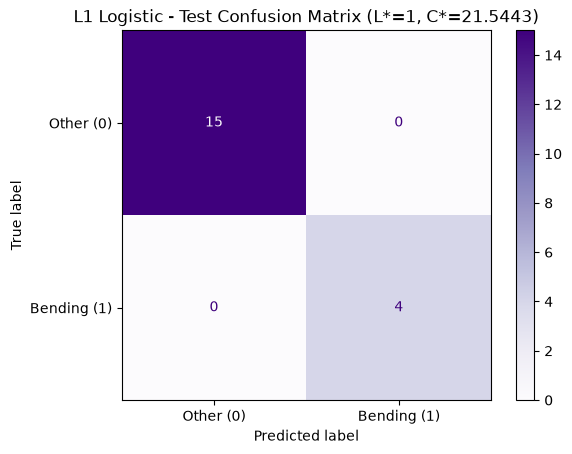

L1 - TN=15, FP=0, FN=0, TP=4
Test accuracy: 1.0000
Test precision: 1.0000
Test recall: 1.0000
Test F1: 1.0000


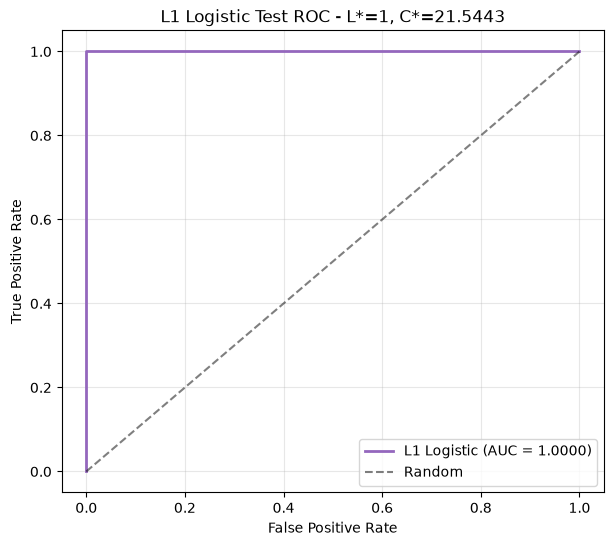

L1 Test AUC: 1.0000


In [22]:
# confusion matrix on test
cm_b = confusion_matrix(y_te_b, test_pred_b)
disp = ConfusionMatrixDisplay(cm_b, display_labels=['Other (0)', 'Bending (1)'])
disp.plot(cmap='Purples', values_format='d')
plt.title(f'L1 Logistic - Test Confusion Matrix (L*={L_star_b}, C*={C_star_b:.4f})')
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm_b.ravel()
print(f"L1 - TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Test accuracy: {accuracy_score(y_te_b, test_pred_b):.4f}")
print(f"Test precision: {precision_score(y_te_b, test_pred_b):.4f}")
print(f"Test recall: {recall_score(y_te_b, test_pred_b):.4f}")
print(f"Test F1: {f1_score(y_te_b, test_pred_b):.4f}")

# ROC + AUC
fpr_b, tpr_b, _ = roc_curve(y_te_b, test_proba_b)
roc_auc_b = auc(fpr_b, tpr_b)

# plot ROC curve
plt.figure(figsize=(7, 6))
plt.plot(fpr_b, tpr_b, color='tab:purple', linewidth=2, 
         label=f'L1 Logistic (AUC = {roc_auc_b:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'L1 Logistic Test ROC - L*={L_star_b}, C*={C_star_b:.4f}')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

print(f"L1 Test AUC: {roc_auc_b:.4f}")

**Observations:**

- Both approaches achieve very high or say near-perfect accuracy on this dataset. The task is almost linearly separable, so most feature selection methods land in similar territory.

## Problem 2(c): Multiclass Classification (All 7 Activities)

### 2(c)(i) L1-penalized multinomial logistic regression

Same approach as 2(b)(i), but now the target is the 7-class activity label. We use multinomial logistic regression with L1 penalty and run `LogisticRegressionCV` over C internally and sweep L externally on the same grid as before

In [23]:
# build multiclass labels (string activity names) from the file list
def build_matrix_L_multiclass(file_list, L):
    rows, labels = [], []
    for filepath, label in file_list:
        df = load_instance(filepath)
        n = len(df)
        seg_size = n // L
        combined = {}
        for seg_idx in range(L):
            start = seg_idx * seg_size
            end = (seg_idx + 1) * seg_size if seg_idx < L - 1 else n
            seg_df = df.iloc[start:end]
            seg_feats = ext_ft(seg_df)
            for k, v in seg_feats.items():
                combined[f"{k}_seg{seg_idx+1}"] = v
        rows.append(combined)
        labels.append(label) # keep the activity string
    X_df = pd.DataFrame(rows)
    return X_df.values, np.array(labels), list(X_df.columns)

# sweep L for multinomial L1
cv_results_c = []
for L in L_values_b:
    X, y, _ = build_matrix_L_multiclass(train_files, L)
    scaler_c = StandardScaler()
    X_scaled = scaler_c.fit_transform(X)
    
    clf_cv = LogisticRegressionCV(   ## llm assisted bugfixing here
        Cs=10,
        penalty='l1',
        solver='saga',
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        scoring='accuracy',
        max_iter=5000,
        random_state=42,
        n_jobs=-1,
    )
    clf_cv.fit(X_scaled, y)
    
    best_C_c = np.mean(list(clf_cv.C_))   # one C per class, take mean for reporting
    cv_score = clf_cv.scores_[list(clf_cv.scores_.keys())[0]].mean(axis=0).max()
    
    cv_results_c.append({
        'L': L,
        'total_features': X.shape[1],
        'best_C': round(best_C_c, 4),
        'cv_accuracy': round(cv_score, 4),
    })
    print(f"L={L:2d} ({X.shape[1]:3d} feats) -> C={best_C_c:.4f}, CV acc={cv_score:.4f}")

cv_results_c_df = pd.DataFrame(cv_results_c)
cv_results_c_df

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 1 ( 42 feats) -> C=2.7826, CV acc=0.9143


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L= 2 ( 84 feats) -> C=2.7826, CV acc=0.8549


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

...

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=15 (630 feats) -> C=166.8101, CV acc=0.8429


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

L=20 (840 feats) -> C=0.3594, CV acc=0.8571


,L,total_features,best_C,cv_accuracy
0,1,42,2.7826,0.9143
1,2,84,2.7826,0.8549
2,5,210,166.8101,0.8429
3,10,420,166.8101,0.8275
4,15,630,166.8101,0.8429
5,20,840,0.3594,0.8571


Best L* = 1, Best C* = 2.7826
CV accuracy: 0.9143


/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt


Test error (multinomial L1): 0.1053
Test accuracy: 0.8947


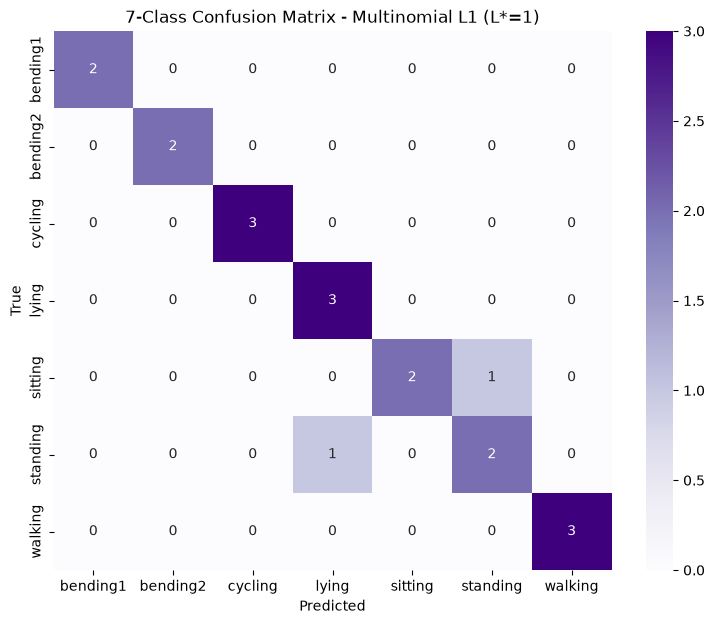

In [24]:
# pick best L for multiclass
best_row_c = cv_results_c_df.iloc[cv_results_c_df['cv_accuracy'].idxmax()]
L_star_c = int(best_row_c['L'])
C_star_c = best_row_c['best_C']
print(f"Best L* = {L_star_c}, Best C* = {C_star_c:.4f}")
print(f"CV accuracy: {best_row_c['cv_accuracy']:.4f}")

# build matrices at L*
X_tr_c, y_tr_c, feat_names_c = build_matrix_L_multiclass(train_files, L_star_c)
X_te_c, y_te_c, _ = build_matrix_L_multiclass(test_files,  L_star_c)

scaler_c_final = StandardScaler()
X_tr_c_scaled = scaler_c_final.fit_transform(X_tr_c)
X_te_c_scaled = scaler_c_final.transform(X_te_c)

final_multi = LogisticRegression(
    C=C_star_c, penalty='l1', solver='saga', max_iter=5000, random_state=42
)
final_multi.fit(X_tr_c_scaled, y_tr_c)

test_pred_c = final_multi.predict(X_te_c_scaled)
test_err_c = 1 - accuracy_score(y_te_c, test_pred_c)
print(f"\nTest error (multinomial L1): {test_err_c:.4f}")
print(f"Test accuracy: {accuracy_score(y_te_c, test_pred_c):.4f}")

# 7-class confusion matrix
cm_c = confusion_matrix(y_te_c, test_pred_c, labels=sorted(set(y_te_c)))
labels_sorted = sorted(set(y_te_c))

plt.figure(figsize=(9, 7))
sns.heatmap(cm_c, annot=True, fmt='d', cmap='Purples',
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title(f'7-Class Confusion Matrix - Multinomial L1 (L*={L_star_c})')
plt.show()

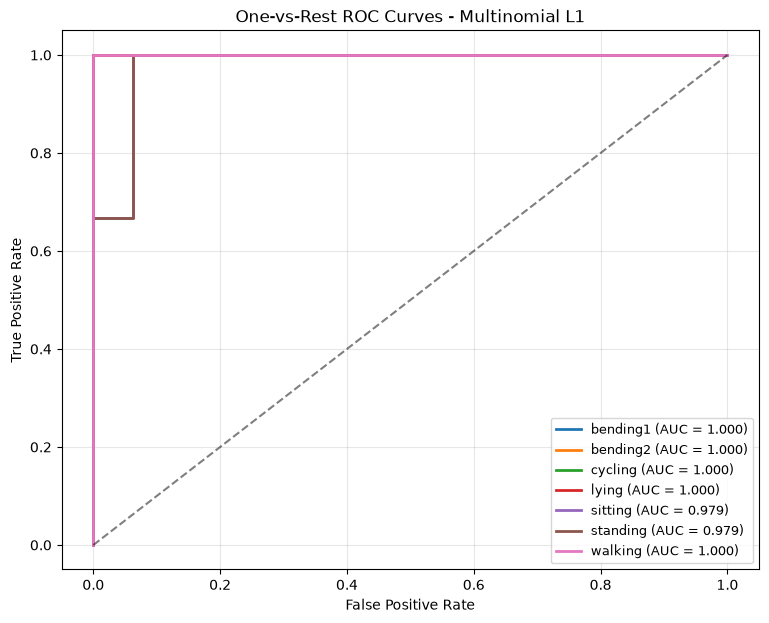

In [25]:
from sklearn.preprocessing import label_binarize

# binarize labels
classes = sorted(set(y_tr_c))
y_te_bin = label_binarize(y_te_c, classes=classes)
test_proba_c = final_multi.predict_proba(X_te_c_scaled)

# plot one-vs-rest ROC curves for each class
plt.figure(figsize=(9, 7))
for i, cls in enumerate(classes):
    fpr_i, tpr_i, _ = roc_curve(y_te_bin[:, i], test_proba_c[:, i])
    auc_i = auc(fpr_i, tpr_i)
    plt.plot(fpr_i, tpr_i, linewidth=2, label=f'{cls} (AUC = {auc_i:.3f})')

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves - Multinomial L1')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.show()

### 2(c)(ii) Naive Bayes (Gaussian + Multinomial)

Repeat multiclass classification using Naive Bayes with two different priors.
- **Gaussian Naive Bayes:** assumes features are normally distributed within each class
- **Multinomial Naive Bayes:** assumes features are counts?

/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(
/var/folders/qw/bmr8kfx53359b9rqb5jnv59w0000gn/T/ipykernel_86892/1906791249.py:13: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='pyt

Gaussian NB test error:  0.1053
Gaussian NB test accuracy: 0.8947

Multinomial NB test error:  0.2105
Multinomial NB test accuracy: 0.7895


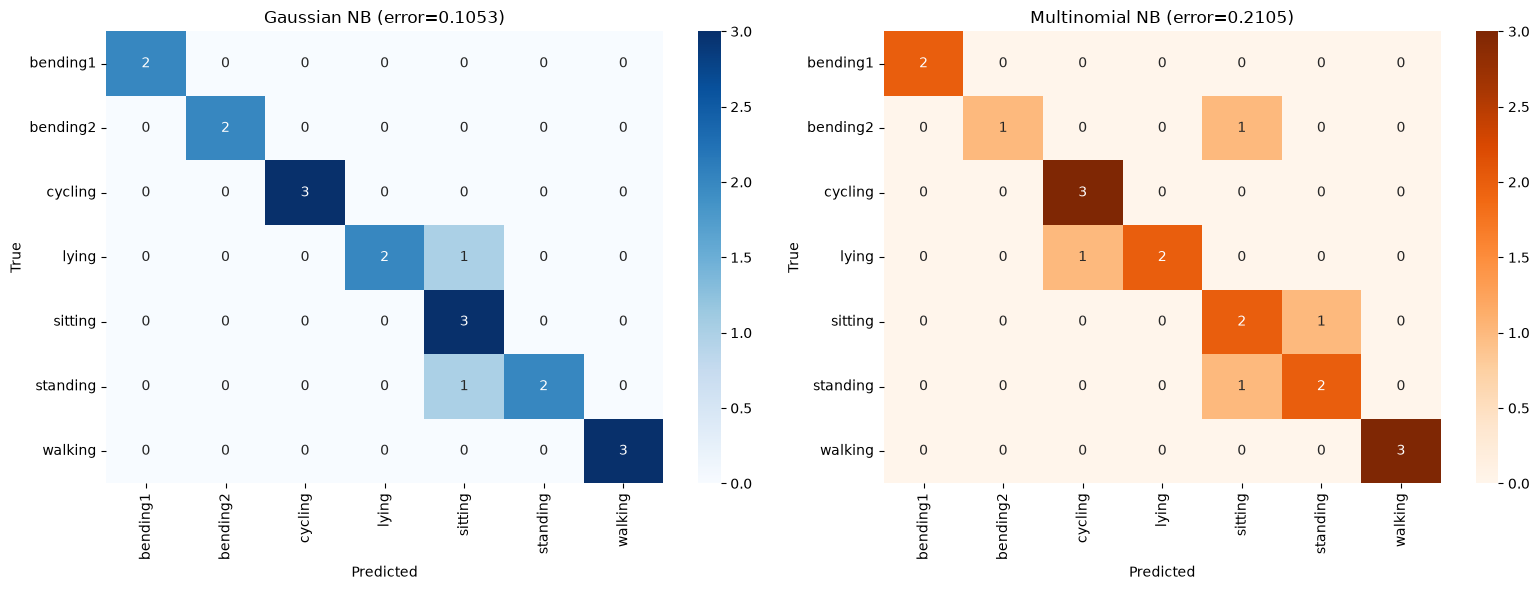

In [26]:
from sklearn.preprocessing import MinMaxScaler

# use the same L* from multinomial L1 for fair comparison
X_tr_nb, y_tr_nb, _ = build_matrix_L_multiclass(train_files, L_star_c)
X_te_nb, y_te_nb, _ = build_matrix_L_multiclass(test_files,  L_star_c)

# Gaussian NB: no need to scale features
gnb = GaussianNB()
gnb.fit(X_tr_nb, y_tr_nb)
gnb_pred = gnb.predict(X_te_nb)
gnb_err = 1 - accuracy_score(y_te_nb, gnb_pred)

print(f"Gaussian NB test error:  {gnb_err:.4f}")
print(f"Gaussian NB test accuracy: {accuracy_score(y_te_nb, gnb_pred):.4f}")

# Multinomial NB: scale features to [0, 1] range
mm = MinMaxScaler()
X_tr_mm = mm.fit_transform(X_tr_nb)
X_te_mm = mm.transform(X_te_nb)

mnb = MultinomialNB()
mnb.fit(X_tr_mm, y_tr_nb)
mnb_pred = mnb.predict(X_te_mm)
mnb_err = 1 - accuracy_score(y_te_nb, mnb_pred)

print(f"\nMultinomial NB test error:  {mnb_err:.4f}")
print(f"Multinomial NB test accuracy: {accuracy_score(y_te_nb, mnb_pred):.4f}")

# confusion matrices side by side
## llm assisted bugfixing here
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
labels_sorted = sorted(set(y_te_nb))

cm_gnb = confusion_matrix(y_te_nb, gnb_pred, labels=labels_sorted)
sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_sorted, yticklabels=labels_sorted, ax=axes[0])
axes[0].set_title(f'Gaussian NB (error={gnb_err:.4f})')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

cm_mnb = confusion_matrix(y_te_nb, mnb_pred, labels=labels_sorted)
sns.heatmap(cm_mnb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=labels_sorted, yticklabels=labels_sorted, ax=axes[1])
axes[1].set_title(f'Multinomial NB (error={mnb_err:.4f})')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')

plt.tight_layout()
plt.show()

**Observations:**

- **Multinomial L1 Logistic and Gaussian NB tied** at 89.47% test accuracy each misclassifying 2 of the 19 tests.
- **Multinomial NB performed worst (78.95%)**, misclassifying 4 instances. This matches theory: Multinomial NB assumes feature distributions suited to discrete count data.

## Problem 3 - ISLR 4.8.3

For K classes with one-dimensional conditional densities $X \mid Y = k \sim \mathcal{N}(\mu_k, \sigma_k^2)$ and class priors $\pi_k$, the Bayes classifier picks the class $k$ that maximizes the posterior. Equivalently, we maximize $\log(\pi_k \, f_k(x))$ since the log is monotonic. Dropping constants that are the same across every class, the discriminant function is:

$$\delta_k(x) = \log \pi_k - \frac{1}{2}\log \sigma_k^2 - \frac{(x - \mu_k)^2}{2\sigma_k^2}.$$

Expanding the squared term inside:

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}\, x^2 + \frac{\mu_k}{\sigma_k^2}\, x - \frac{\mu_k^2}{2\sigma_k^2} - \frac{1}{2}\log \sigma_k^2 + \log \pi_k.$$

The coefficient on $x^2$ here is $-\dfrac{1}{2\sigma_k^2}$. This coefficient depends on $k$ because $\sigma_k^2$ differs across classes.

The decision boundary between any two classes $k$ and $j$ is where $\delta_k(x) = \delta_j(x)$. Setting them equal and collecting terms gives:

$$\left(\frac{1}{2\sigma_j^2} - \frac{1}{2\sigma_k^2}\right) x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_j}{\sigma_j^2}\right) x + \text{constants} = 0.$$

The leading $x^2$ coefficient is nonzero whenever $\sigma_k^2 \ne \sigma_j^2$. So the boundary is a quadratic equation in $x$, not linear. This is why QDA produces quadratic boundaries.

Note that if we add the LDA assumption that all classes share the same variance $\sigma_1^2 = \sigma_2^2 = \cdots = \sigma_K^2$, the $x^2$ terms cancel between any two classes and we are left with a linear boundary. The quadratic shape under QDA comes exactly from allowing class-specific variances.

## Problem 4 - ISLR 4.8.7

both classes share variance as $\sigma^2 = 36$, so $\sigma = 6$.

$$P(\text{Yes} \mid X = x) = \frac{\pi_Y \, f_Y(x)}{\pi_Y \, f_Y(x) + \pi_N \, f_N(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(x - \mu_k)^2}{2\sigma^2}\right)$$

where given $\pi_Y = 0.8$, $\mu_Y = 10$, $\pi_N = 0.2$, $\mu_N = 0$.

Since both densities use the same $\sigma^2$, the factor $1/\sqrt{2\pi\sigma^2}$ is the same for Yes and No. It cancels in the numerator and denominator of the posterior. We only need the ratio of $\pi_k \, \exp(\cdot)$ terms.

For $x = 4$:

$$P(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}} = \frac{0.8\, e^{-1/2}}{0.8\, e^{-1/2} + 0.2\, e^{-2/9}}$$

Evaluating the exponentials:

$$= \frac{0.8 \times 0.60653}{0.8 \times 0.60653 + 0.2 \times 0.80074} = \frac{0.48522}{0.64537} \approx 0.752.$$

So the probability that the company issues a dividend is about **75.2%**. The observed profit $X = 4$ is actually closer to the "No" mean of 0 than to the "Yes" mean of 10, but the strong prior (80% of companies issue dividends) still pushes the posterior toward Yes.

### For the above problems, I used an LLM to help me format my answers in VSCode as it was difficult to write it in format at the start. 